# Learning After Training

*The Mathematics of Machine Intelligence · Chapter 27*

Change a trained mind on purpose, and see what each way of doing it costs.

These pages illustrate the mathematics. Read the saved figures and calculations in order, or open [the interactive browser edition](reader.html) to change the examples. No code editing is needed. Every figure is computed from the chapter's own equations or from a disclosed simulation; a simulation is not a measurement, and the mathematics of a brain is a model.

Ask what must be kept (old examples, old weights and sensitivity numbers, or the adapter), what is lost (new skill, old skill, or time), and whether the change can be undone. Use the adapter card for sizes, the penalty card for how far each weight moves, and the toy card for the direction and price of each fix in a small case. Say that the toy is not a published study and does not show that real adapters forget more.

<details><summary>Reproducing these calculations</summary>

The optional calculation cells use Python with NumPy and Matplotlib. All inputs, random seeds and functions are included in this file. The figures below are saved, so running these cells is optional.

</details>

In [1]:
import io
import math
import re
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from cycler import cycler
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13, 'axes.labelsize': 11, 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#7d8588', 'axes.labelcolor': '#172a3b', 'text.color': '#172a3b', 'xtick.color': '#52606b', 'ytick.color': '#52606b', 'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'grid.alpha': 0.2, 'lines.linewidth': 2, 'svg.fonttype': 'path', 'axes.unicode_minus': False})
plt.rcParams['axes.prop_cycle'] = cycler(color=['#136f75', '#b77518', '#334c72', '#aa4e37', '#677341'])

def clean_display_text(text):
    """Remove signed zero only after an explicitly formatted value rounds to zero."""
    return re.sub(r"(?<![\w.])-(?:0+(?:\.0*)?|\.0+)(?:[eE][+-]?\d+)?(?![\w.])", "0", text)


def display_value(value):
    """One display policy for readers, saved notebooks and skill references."""
    if hasattr(value, "item") and getattr(value, "size", 1) == 1:
        value = value.item()
    if isinstance(value, float):
        if not math.isfinite(value):
            raise ValueError("Return undefined or infinity as a labeled string, not a nonfinite JSON value")
        return "0" if value == 0 else f"{value:.6g}"
    if isinstance(value, str):
        return clean_display_text(value)
    if isinstance(value, (list, tuple)):
        opening, closing = ("(", ")") if isinstance(value, tuple) else ("[", "]")
        return opening + ", ".join(str(display_value(v)) for v in value) + closing
    if isinstance(value, dict):
        return "{" + ", ".join(str(k) + ": " + str(display_value(v)) for k, v in value.items()) + "}"
    return value


"""Chapter 27, Learning After Training: executable mathematics and reader-facing teaching content."""
from functools import lru_cache
import numpy as np
import matplotlib.pyplot as plt
NAVY = '#17324d'
TEAL = '#147d86'
GOLD = '#d8a23c'
DARK_GOLD = '#8a5a0f'
TERRA = '#bf6045'
GREY = '#7d8588'

def sig(value, digits=3):
    """Three significant figures; values that are zero up to round-off show as 0."""
    value = float(value)
    if abs(value) < 1e-12:
        return '0'
    return f'{value:.{digits}g}'

def panels(ratios=None):
    kwargs = {'gridspec_kw': {'width_ratios': ratios}} if ratios else {}
    fig, axes = plt.subplots(1, 2, figsize=(8, 4.2), layout='constrained', **kwargs)
    for ax in axes:
        ax.grid(alpha=0.15)
    return (fig, axes)

def tag(ax, x, y, text, **kwargs):
    """A label with a white backing so it stays legible over lines."""
    kwargs.setdefault('fontsize', 10)
    kwargs.setdefault('ha', 'center')
    ax.text(x, y, text, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1.5, 'alpha': 0.9}, **kwargs)

def ring(ax, x, y):
    ax.plot([x], [y], marker='o', markersize=11, markerfacecolor='none', markeredgecolor=NAVY, markeredgewidth=2.2, zorder=6)
W_LAYER = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
B_COLUMNS = np.array([[1, 0, 1], [2, 1, 0], [0, 1, 0]])
A_ROWS = np.array([[1, 0, -1], [0, 1, 0], [0, 0, 1]])

def adapter_product(rank):
    """B A for the first `rank` pairs of columns and rows."""
    return B_COLUMNS[:, :rank] @ A_ROWS[:rank, :]

def adapter_numbers(d_out, d_in, rank):
    """Numbers in B (d_out by r) and A (r by d_in)."""
    return rank * (d_out + d_in)

def draw_grid(ax, matrix, title, highlight=None, fmt='{:g}'):
    ax.imshow(np.zeros(matrix.shape), cmap='Greys', vmin=0, vmax=1, alpha=0.04)
    for (i, j), v in np.ndenumerate(matrix):
        changed = highlight is not None and highlight[i, j]
        ax.text(j, i, fmt.format(v), ha='center', va='center', fontsize=15, color=TERRA if changed else NAVY, fontweight='bold' if changed else 'normal')
    ax.set_xticks(range(matrix.shape[1]))
    ax.set_yticks(range(matrix.shape[0]))
    ax.set_xticklabels([str(j + 1) for j in range(matrix.shape[1])])
    ax.set_yticklabels([str(i + 1) for i in range(matrix.shape[0])])
    ax.set_xticks(np.arange(-0.5, matrix.shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, matrix.shape[0], 1), minor=True)
    ax.grid(which='minor', color='#d0d6d8', linewidth=1)
    ax.grid(which='major', visible=False)
    ax.tick_params(which='minor', length=0)
    ax.set_title(title, fontsize=11)
    ax.set(xlabel='column', ylabel='row')

def lora_picture(rank=1):
    change = adapter_product(rank)
    adapted = W_LAYER + change
    fig, ax = panels()
    draw_grid(ax[0], change, f'The change B A (rank at most {rank})', highlight=change != 0)
    draw_grid(ax[1], adapted, 'The adapted layer W + B A', highlight=change != 0)
    trained = adapter_numbers(3, 3, rank)
    actual_rank = int(np.linalg.matrix_rank(change))
    metrics = {'Top row of W + B A': ', '.join((str(v) for v in adapted[0])), 'Rank of B A': str(actual_rank), 'Numbers in the adapter (B and A)': str(trained), 'Numbers in the full layer': '9'}
    saves = 'fewer than' if trained < 9 else 'more than'
    summary = f"With rank {rank} the adapter holds {trained} numbers, {saves} the 9 in the full 3 by 3 layer. The top row of W becomes ({', '.join((str(v) for v in adapted[0]))}) and the change has rank {actual_rank}. An adapter saves numbers only when its rank is below half the layer width."
    parts = {1: '(1, 2, 0) x (1, 0, -1)', 2: 'adds (0, 1, 1) x (0, 1, 0)', 3: 'adds (1, 0, 0) x (0, 0, 1)'}
    calc = f'Rank {rank}: {parts[1]}' + ('' if rank == 1 else f' and {parts[2]}') + ('' if rank < 3 else f' and {parts[3]}') + f'. Each row of a column-by-row product is one entry of the column times the whole row. Numbers trained: 2 x 3 x {rank} = {trained}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
LAYER_WIDTHS = [512, 1024, 4096, 8192]
RANKS = [1, 4, 8, 16, 64]

def adapter_share(d, rank):
    """Adapter numbers divided by the numbers in a d by d layer: 2 d r / d^2 = 2 r / d."""
    return adapter_numbers(d, d, rank) / (d * d)

def size_picture(layer=4096, rank=8):
    full = layer * layer
    adapter = adapter_numbers(layer, layer, rank)
    share = adapter / full
    fig, ax = panels()
    ax[0].bar([0, 1], [full, adapter], color=[GREY, TEAL], width=0.55)
    ax[0].set_yscale('log')
    for x, v in ((0, full), (1, adapter)):
        tag(ax[0], x, v * 1.5, f'{v:,}', va='bottom', fontsize=10)
    ax[0].set_xticks([0, 1])
    ax[0].set_xticklabels(['full layer', f'rank-{rank} adapter'])
    ax[0].set(ylabel='numbers (log scale)', ylim=(100.0, 3000000000.0), title=f'A {layer:,} by {layer:,} layer')
    grid = np.array(sorted(set([1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048, 4096])))
    for d, color in zip(LAYER_WIDTHS, [TERRA, DARK_GOLD, TEAL, NAVY]):
        mask = grid <= d
        ax[1].plot(grid[mask], [100 * adapter_share(d, r) for r in grid[mask]], color=color, linewidth=2.6 if d == layer else 1.1, alpha=1 if d == layer else 0.6, label=f'width {d:,}')
    ring(ax[1], rank, 100 * share)
    ax[1].axhline(100, color=GREY, linestyle='dashed', linewidth=1)
    tag(ax[1], 3, 150, 'as large as the layer', fontsize=9)
    ax[1].set(xscale='log', yscale='log', xlabel='adapter rank', ylabel='adapter size as percent of the layer', ylim=(0.01, 1000), title='Every case, selected one ringed')
    ax[1].legend(fontsize=8.5, loc='lower right')
    metrics = {'Numbers in the full layer': f'{full:,}', 'Numbers in the adapter': f'{adapter:,}', 'Adapter share of the layer': f'{sig(100 * share)} percent (1 in {full // adapter:,})', 'Rank at which the adapter is as large as the layer': f'{layer // 2:,}'}
    summary = f'A {layer:,} by {layer:,} layer holds {full:,} numbers. A rank-{rank} adapter holds {adapter:,}, which is {sig(100 * share)} percent. The adapter stops saving anything at rank {layer // 2:,}, half the width.'
    calc = f'Full layer: {layer:,} x {layer:,} = {full:,}. Adapter: B has {layer:,} x {rank} and A has {rank} x {layer:,}, so 2 x {layer:,} x {rank} = {adapter:,}. Share = 2 x {rank} / {layer:,} = {sig(share, 4)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
OLD_VALUES = np.array([2.0, 2.0])
FISHER_2 = 0.25

def ewc_minimum(lam, f1, f2=FISHER_2):
    """Each weight settles at a weighted average of the new target 0 and its old value 2: (lam F x 2) / (1 + lam F)."""
    fisher = np.array([f1, f2])
    return lam * fisher * OLD_VALUES / (1.0 + lam * fisher)

def ewc_costs(theta, lam, f1, f2=FISHER_2):
    """New-task loss (theta1^2 + theta2^2) / 2 and the penalty sum of (lam / 2) F (theta - old)^2."""
    theta = np.asarray(theta, dtype=float)
    fisher = np.array([f1, f2])
    new_loss = float((theta ** 2).sum() / 2.0)
    penalty = float((lam / 2.0 * fisher * (theta - OLD_VALUES) ** 2).sum())
    return (new_loss, penalty)
LAMBDAS = [0.0, 0.25, 0.5, 1.0, 2.0, 5.0, 20.0]
FISHER_1 = [1.0, 4.0, 16.0]

def ewc_picture(lam=1.0, f1=4.0):
    theta = ewc_minimum(lam, f1)
    new_loss, penalty = ewc_costs(theta, lam, f1)
    fig, ax = panels()
    xs, ys = np.meshgrid(np.linspace(-0.3, 2.4, 200), np.linspace(-0.3, 2.4, 200))
    total = (xs ** 2 + ys ** 2) / 2 + lam / 2 * (f1 * (xs - 2) ** 2 + FISHER_2 * (ys - 2) ** 2)
    ax[0].contour(xs, ys, total, levels=10, colors=GREY, linewidths=0.8, alpha=0.7)
    path = np.array([ewc_minimum(l, f1) for l in np.linspace(0, 20, 120)])
    ax[0].plot(path[:, 0], path[:, 1], color=TEAL, linewidth=1.6, linestyle='dashed', label='compromise as lambda grows')
    ax[0].plot([2], [2], marker='s', color=GOLD, markersize=10, linestyle='none', label='old values (2, 2)')
    ax[0].plot([0], [0], marker='^', color=TERRA, markersize=10, linestyle='none', label='new-task optimum (0, 0)')
    ax[0].plot([theta[0]], [theta[1]], marker='o', color=NAVY, markersize=10, linestyle='none', label=f'compromise ({theta[0]:.2f}, {theta[1]:.2f})')
    ax[0].legend(fontsize=7.5, loc='upper left')
    ax[0].set(xlabel='weight 1 (mattered to task A)', ylabel='weight 2 (hardly mattered)', xlim=(-0.3, 2.4), ylim=(-0.3, 2.9), title=f'Lambda {lam:g}, Fisher number {f1:g} and 0.25')
    grid = np.linspace(0, 20, 120)
    for f, color in zip(FISHER_1, [TERRA, NAVY, TEAL]):
        ax[1].plot(grid, [ewc_minimum(l, f)[0] for l in grid], color=color, linewidth=2.6 if f == f1 else 1.1, alpha=1 if f == f1 else 0.6, label=f'weight 1, F = {f:g}')
    ax[1].plot(grid, [ewc_minimum(l, f1)[1] for l in grid], color=GREY, linestyle='dashed', linewidth=1.6, label='weight 2, F = 0.25')
    ring(ax[1], lam, theta[0])
    ring(ax[1], lam, theta[1])
    ax[1].legend(fontsize=7.5, loc='center right')
    ax[1].set(xlabel='lambda (how much the old task counts)', ylabel='where the weight settles', ylim=(-0.05, 2.15), xlim=(0, 20), title='Every case, selected one ringed')
    stay = ewc_costs(OLD_VALUES, lam, f1)
    zero = ewc_costs([0.0, 0.0], lam, f1)
    metrics = {'Weight 1 settles at': sig(theta[0]), 'Weight 2 settles at': sig(theta[1]), 'Total cost at (2, 2) and at (0, 0)': f'{sig(sum(stay))} and {sig(sum(zero))}', 'Total cost at the compromise': sig(new_loss + penalty)}
    summary = f'At lambda {lam:g} the weight that mattered (Fisher number {f1:g}) settles at {sig(theta[0])}, moving {sig(2 - theta[0])} from 2, and the weight that hardly mattered settles at {sig(theta[1])}, moving {sig(2 - theta[1])}. A larger lambda keeps both nearer 2.'
    calc = f'Position = (lambda F x 2) / (1 + lambda F). Weight 1: ({sig(lam * f1)} x 2) / (1 + {sig(lam * f1)}) = {sig(theta[0])}. Weight 2: ({sig(lam * FISHER_2)} x 2) / (1 + {sig(lam * FISHER_2)}) = {sig(theta[1])}. Cost = new-task loss {sig(new_loss)} + penalty {sig(penalty)} = {sig(new_loss + penalty)}.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
TAXI = {'hours': ('Training hours per week', 34.56, 16.7, 'hours per week'), 'appearances': ('Test appearances', 15.64, 2.6, 'appearances'), 'months': ('Total months of training', 38.8, 35.8, 'months')}
TAXI_ORDER = ['hours', 'appearances', 'months']
COHORT = {'started': 79, 'qualified': 39, 'not_qualified': 20, 'did_not_return': 20, 'comparison': 31}

def taxi_ratio(measure):
    """Not qualified divided by qualified."""
    _, qualified, not_qualified, _ = TAXI[measure]
    return not_qualified / qualified

def taxi_picture(measure='hours'):
    label, q, n, unit = TAXI[measure]
    fig, ax = panels()
    bars = ax[0].bar([0, 1], [q, n], color=[TEAL, GOLD], width=0.55)
    for b, v in zip(bars, (q, n)):
        tag(ax[0], b.get_x() + b.get_width() / 2, v + max(q, n) * 0.02, f'{v:g}', va='bottom', fontsize=11)
    ax[0].set_xticks([0, 1])
    ax[0].set_xticklabels(['qualified (39)', 'did not qualify (20)'], fontsize=9)
    ax[0].set(ylabel=unit, ylim=(0, max(q, n) * 1.15), title=label)
    xs = np.arange(3)
    ratios = [taxi_ratio(k) for k in TAXI_ORDER]
    ax[1].bar(xs, ratios, color=[NAVY if k == measure else TEAL for k in TAXI_ORDER], width=0.55)
    for x, v in zip(xs, ratios):
        tag(ax[1], x, v + 0.03, f'{v:.2f}', va='bottom', fontsize=11)
    ax[1].axhline(1.0, color=GREY, linestyle='dashed', linewidth=1.2)
    ax[1].set_xticks(xs)
    ax[1].set_xticklabels(['hours\nper week', 'test\nappearances', 'months of\ntraining'], fontsize=8.5)
    ax[1].set(ylabel='did not qualify divided by qualified', ylim=(0, 1.2), title='Months alike, intensity lower')
    ratio = taxi_ratio(measure)
    metrics = {'Qualified': f'{q:g} {unit}', 'Did not qualify': f'{n:g} {unit}', "Ratio, not qualified to qualified (companion's arithmetic)": f'{ratio:.2f}', 'Cohort': '79 started; 59 returned (39 and 20); 31 comparison men'}
    summary = f'On {label.lower()}, the men who did not qualify had {n:g} against {q:g} for those who did, a ratio of {ratio:.2f}. Total months of training were similar (38.8 against 35.8), while weekly hours and appearances were far lower.'
    calc = f'Ratio = {n:g} / {q:g} = {ratio:.3f}. Cohort check: 39 + 20 + 20 who did not return = 79 at the first scan.'
    return (fig, metrics, {'summary': summary, 'calculation': calc})
D_IN, H_UNITS, K_OUT = (16, 12, 3)
LEARNING_RATE, UPDATES = (0.2, 1500)
N_PARAMS = H_UNITS * D_IN + H_UNITS + K_OUT * H_UNITS + K_OUT
SEEDS = tuple(range(20))
EARLY_THRESHOLD = 0.95

def softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

def forward(p, X):
    h = np.tanh(X @ p['W1'].T + p['b1'])
    return (h, softmax(h @ p['W2'].T + p['b2']))

def gradients(p, X, Y):
    n = len(X)
    h, P = forward(p, X)
    G = (P - np.eye(K_OUT)[Y]) / n
    g = {'W2': G.T @ h, 'b2': G.sum(0)}
    dh = G @ p['W2'] * (1 - h ** 2)
    g['W1'] = dh.T @ X
    g['b1'] = dh.sum(0)
    return g

def accuracy(p, X, Y):
    return float((forward(p, X)[1].argmax(1) == Y).mean())

def make_tasks(seed, spread=0.8, n=90):
    """Task A: three groups of points, each a fixed prototype plus noise. Task B: the same kind, with the 16 inputs in a fixed shuffled order."""
    r = np.random.default_rng(seed)
    prototypes = r.normal(size=(K_OUT, D_IN))
    perm = r.permutation(D_IN)

    def sample(m, order=None):
        y = np.repeat(np.arange(K_OUT), m // K_OUT)
        X = prototypes[y] + spread * r.normal(size=(len(y), D_IN))
        if order is not None:
            X = X[:, order]
        return (X, y)
    return {'A': sample(n), 'B': sample(n, perm), 'A_test': sample(900), 'B_test': sample(900, perm)}

def initial_weights(r):
    return {'W1': r.normal(size=(H_UNITS, D_IN)) * 0.3, 'b1': np.zeros(H_UNITS), 'W2': r.normal(size=(K_OUT, H_UNITS)) * 0.3, 'b2': np.zeros(K_OUT)}

def train(p, X, Y, lr=LEARNING_RATE, steps=UPDATES, extra=None, stop_on=None):
    """Full-batch gradient descent. `extra(p)` adds gradient terms (the penalty). `stop_on=(X, Y)` stops once accuracy there reaches 95 percent."""
    p = {k: v.copy() for k, v in p.items()}
    for _ in range(steps):
        if stop_on is not None and accuracy(p, *stop_on) >= EARLY_THRESHOLD:
            break
        g = gradients(p, X, Y)
        if extra:
            for k, v in extra(p).items():
                g[k] = g[k] + v
        for k in p:
            p[k] -= lr * g[k]
    return p

def fisher_numbers(p, X):
    """Diagonal Fisher: mean over old cards of the model-weighted squared gradient of log p(answer | card), exact over the 3 answers."""
    F = {k: np.zeros_like(v) for k, v in p.items()}
    for i in range(len(X)):
        x = X[i:i + 1]
        P = forward(p, x)[1]
        for y in range(K_OUT):
            g = gradients(p, x, np.array([y]))
            for k in F:
                F[k] += P[0, y] * g[k] ** 2
    return {k: v / len(X) for k, v in F.items()}

def train_adapter(p, X, Y, rank, seed, lr=LEARNING_RATE, steps=UPDATES, stop_on=None):
    """Freeze p. Train only B (hidden by rank, starts at 0) and A (rank by inputs, random) so the first layer is W1 + B A."""
    r = np.random.default_rng(seed)
    q = {k: v.copy() for k, v in p.items()}
    B = np.zeros((H_UNITS, rank))
    A = r.normal(size=(rank, D_IN)) * 0.3
    for _ in range(steps):
        q['W1'] = p['W1'] + B @ A
        if stop_on is not None and accuracy(q, *stop_on) >= EARLY_THRESHOLD:
            break
        g = gradients(q, X, Y)['W1']
        gB, gA = (g @ A.T, B.T @ g)
        B -= lr * gB
        A -= lr * gA
    q['W1'] = p['W1'] + B @ A
    return (q, B, A)
FIXES = ['plain', 'replay10', 'replay90', 'penalty10', 'penalty1000', 'adapter2', 'adapter_removed']
FIX_LABELS = {'plain': 'plain fine-tuning', 'replay10': 'replay of 10 old cards', 'replay90': 'replay of all 90 old cards', 'penalty10': 'penalty, lambda 10', 'penalty1000': 'penalty, lambda 1,000', 'adapter2': 'rank-2 adapter', 'adapter_removed': 'adapter removed'}
STORED = {'plain': 'nothing extra', 'replay10': '10 old cards (160 numbers and 10 labels)', 'replay90': '90 old cards (1,440 numbers and 90 labels)', 'penalty10': '486 numbers (old weights and Fisher numbers)', 'penalty1000': '486 numbers (old weights and Fisher numbers)', 'adapter2': '56 numbers (the adapter)', 'adapter_removed': '56 numbers (the adapter, now unused)'}
STOPS = ['full length', 'early stop']

def accuracies(p, tasks):
    return (accuracy(p, *tasks['A_test']), accuracy(p, *tasks['B_test']))

def run_toy_seed(seed):
    """All conditions for one random version of the toy. Returns {(stop, fix): (accuracy on A, accuracy on B)} plus the reference points."""
    tasks = make_tasks(seed)
    p0 = initial_weights(np.random.default_rng(1000 + seed))
    (XA, YA), (XB, YB) = (tasks['A'], tasks['B'])
    pA = train(p0, XA, YA)
    F = fisher_numbers(pA, XA)
    out = {'after A': accuracies(pA, tasks)}
    for stop in STOPS:
        guard = (XB, YB) if stop == 'early stop' else None
        out[stop, 'plain'] = accuracies(train(pA, XB, YB, stop_on=guard), tasks)
        for key, k in (('replay10', 10), ('replay90', 90)):
            idx = np.arange(0, 90, 90 // k)[:k]
            X, Y = (np.vstack([XB, XA[idx]]), np.concatenate([YB, YA[idx]]))
            out[stop, key] = accuracies(train(pA, X, Y, stop_on=guard), tasks)
        for key, lam in (('penalty10', 10), ('penalty1000', 1000)):
            extra = lambda p, lam=lam: {k: lam * F[k] * (p[k] - pA[k]) for k in p}
            out[stop, key] = accuracies(train(pA, XB, YB, extra=extra, stop_on=guard), tasks)
        q, _, _ = train_adapter(pA, XB, YB, 2, seed, stop_on=guard)
        out[stop, 'adapter2'] = accuracies(q, tasks)
        removed = {k: v.copy() for k, v in q.items()}
        removed['W1'] = pA['W1']
        out[stop, 'adapter_removed'] = accuracies(removed, tasks)
    joint = train(p0, np.vstack([XA, XB]), np.concatenate([YA, YB]), steps=3000)
    out['both from the start'] = accuracies(joint, tasks)
    return out

@lru_cache(maxsize=None)
def toy_results(seeds=SEEDS):
    """Average accuracy over the seeded versions of the toy, in percent, for every condition."""
    per_seed = [run_toy_seed(s) for s in seeds]
    return {key: tuple((float(100.0 * np.mean([r[key][i] for r in per_seed])) for i in range(2))) for key in per_seed[0]}

def toy_picture(fix='plain', stop='full length'):
    res = toy_results()
    a, b = res[stop, fix]
    a0, b0 = res['after A']
    fig, ax = panels()
    ax[0].bar([0, 1], [a, b], color=[NAVY, TEAL], width=0.55)
    ax[0].scatter([0, 1], [a0, b0], marker='_', s=900, color=TERRA, zorder=5, linewidths=2.2, label='after learning A')
    ax[0].axhline(100 / 3, color=GREY, linestyle='dotted', linewidth=1.2)
    tag(ax[0], 0.5, 100 / 3 + 3, 'guessing: 33', fontsize=9)
    for x, v in ((0, a), (1, b)):
        tag(ax[0], x, min(v + 3, 108), f'{v:.0f}', va='bottom', fontsize=11)
    ax[0].set_xticks([0, 1])
    ax[0].set_xticklabels(['old task A', 'new task B'])
    ax[0].legend(fontsize=8.5, loc='upper center', ncol=1)
    ax[0].set(ylabel='accuracy on fresh cards (percent)', ylim=(0, 128), title=f'{FIX_LABELS[fix]}, {stop}', yticks=[0, 20, 40, 60, 80, 100])
    rows = [('after A', res['after A']), ('both from the start', res['both from the start'])] + [(FIX_LABELS[k], res[stop, k]) for k in FIXES]
    keys = ['after A', 'both'] + FIXES
    ys = np.arange(len(rows))[::-1] * 1.0
    for y, (name, (ca, cb)), key in zip(ys, rows, keys):
        on = key == fix
        if on:
            ax[1].axhspan(y - 0.5, y + 0.5, color='#f3e6c8', zorder=0)
        ax[1].barh(y + 0.17, ca, height=0.32, color=NAVY)
        ax[1].barh(y - 0.17, cb, height=0.32, color=TEAL)
        ax[1].text(ca + 1, y + 0.17, f'{ca:.0f}', va='center', fontsize=7.5)
        ax[1].text(cb + 1, y - 0.17, f'{cb:.0f}', va='center', fontsize=7.5)
    ax[1].set_yticks(ys)
    ax[1].set_yticklabels([r[0] for r in rows], fontsize=8)
    ax[1].set_xticks([0, 20, 40, 60, 80, 100])
    ax[1].axvline(100 / 3, color=GREY, linestyle='dotted', linewidth=1)
    ax[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=NAVY), plt.Rectangle((0, 0), 1, 1, color=TEAL)], labels=['old task A', 'new task B'], fontsize=8, loc='center right', bbox_to_anchor=(1.0, 0.5))
    ax[1].set(xlabel='accuracy (percent), dotted line: guessing', xlim=(0, 175), ylim=(-0.7, len(rows) - 0.3), title=f'Every fix, {stop}')
    ax[1].xaxis.label.set_fontsize(9)
    metrics = {'Old task A': f'{a:.0f} percent', 'New task B': f'{b:.0f} percent', 'Change on A from before B': f'{a - a0:+.0f} points', 'Extra to store': STORED[fix]}
    summary = f'{FIX_LABELS[fix].capitalize()} ({stop}) leaves task A at {a:.0f} percent and task B at {b:.0f}. ' + (f'Removal restores the frozen original weights by construction, so this row checks the code and is not a finding (average of 20 seeded toy networks).' if fix == 'adapter_removed' else f"Before B, A was {a0:.0f} and B {b0:.0f}. This is the average of 20 seeded versions of a toy network, a companion rerun of the chapter's script, not a model of a real system.")
    calc = f'Accuracy is the share of 900 fresh cards sorted correctly, averaged over 20 random versions (seeds 0 to 19); guessing is 33 percent. Network: 16 inputs, 12 tanh units, 3 outputs, {N_PARAMS} weights. 1,500 updates per stage at learning rate 0.2' + ('; the B stage stops at 95 percent on its 90 training cards.' if stop == 'early stop' else '.')
    return (fig, metrics, {'summary': summary, 'calculation': calc})

## C27-D01: What does a column times a row add to a layer?

A layer W is the 3 by 3 grid with top row (1, 2, 3). An adapter adds the column (1, 2, 0) times the row (1, 0, -1). What is the adapted layer, and how many numbers did the adapter hold?

To multiply a column by a row, multiply each number in the column by the whole row. The result has the same shape as W, so the two add. The change has rank at most r, the width of B and A. At width 1 every row of the change is a multiple of one row.

$$
W'=W+BA
$$

**Symbols:** W: the original layer, d rows by k columns, kept frozen; B: a tall thin grid, d rows by r columns; A: a wide thin grid, r rows by k columns; r: the adapter width, an upper bound on the rank of the change

**Predict before looking:** Predict the top row of W plus B A, and whether a rank-2 adapter on this 3 by 3 layer holds fewer numbers than the layer.

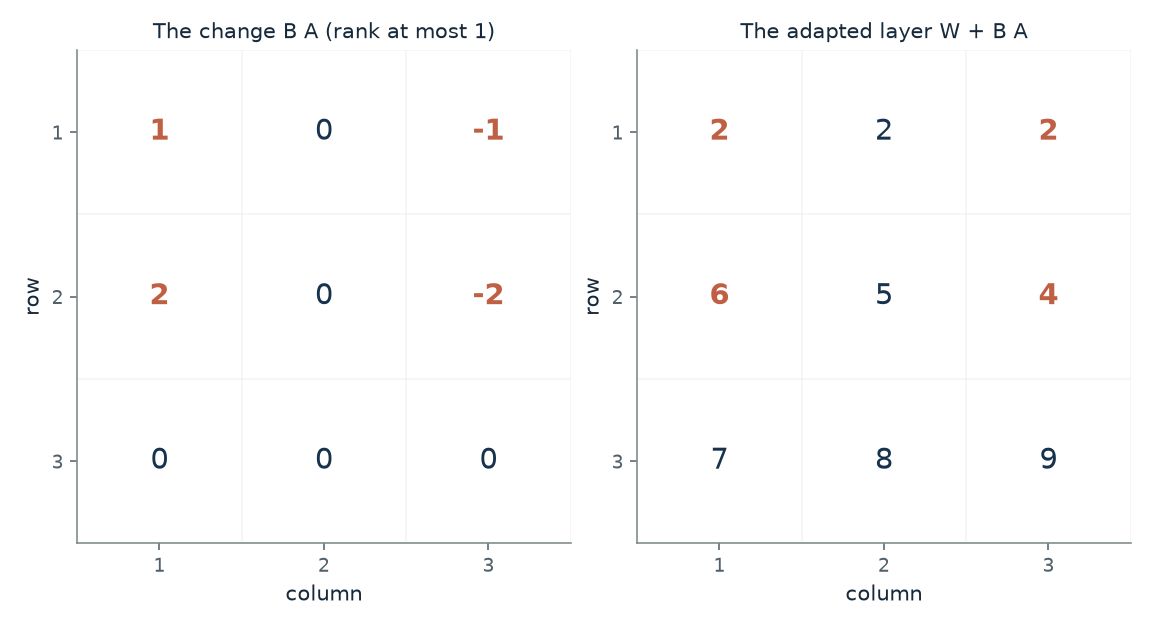

- **Top row of W + B A:** 2, 2, 2
- **Rank of B A:** 1
- **Numbers in the adapter (B and A):** 6
- **Numbers in the full layer:** 9

With rank 1 the adapter holds 6 numbers, fewer than the 9 in the full 3 by 3 layer. The top row of W becomes (2, 2, 2) and the change has rank 1. An adapter saves numbers only when its rank is below half the layer width.

Rank 1: (1, 2, 0) x (1, 0, -1). Each row of a column-by-row product is one entry of the column times the whole row. Numbers trained: 2 x 3 x 1 = 6.

In [2]:
figure, values, explanation = lora_picture(**{'rank': 1})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='What does a column times a row add to a layer?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Adapter rank r = 1: The rows of B A are the row (1, 0, -1) unchanged, doubled, and zeroed, so the top row of W becomes (2, 2, 2). The rank-1 adapter holds 6 numbers against 9. At rank 2 it holds 12, more than the layer: an adapter saves numbers only when its rank is below half the width.

**Takeaway:** A rank-1 change is one column times one row: every row of the change is a multiple of the same row. The adapter saves numbers only when r is below half the layer width.

**Why it matters:** A small adapter lets a company store a change as two thin grids instead of a full copy. The saving depends on the layer width and the adapter rank, which the next demonstration sizes at real scale.

**In machines:** This is a specification of how a LoRA update is built, an arithmetic identity rather than a model of behavior. Whether a task needs only a low-rank change is a hypothesis about tasks.

**Where it applies:** A frozen W and a trained B and A, with the change to the layer built from their product. The 3 by 3 case is too small for an adapter to save much; it is shown to make the product visible.

**Check your understanding:** With B = (1, 2, 0) and A = (1, 0, -1), what are the second and third rows of B A, and what are the second and third rows of W plus B A?

<details><summary>Show the answer</summary>

Row 2 of B A is 2 x (1, 0, -1) = (2, 0, -2) and row 3 is 0 x (1, 0, -1) = (0, 0, 0). So W plus B A has second row (4, 5, 6) + (2, 0, -2) = (6, 5, 4) and third row (7, 8, 9).

</details>

*Source: Chapter 27, Changing the weights on purpose is routine, and a small adapter makes it cheap. Book formula and constructed example (the chapter's rank-1 case: B = (1, 2, 0), A = (1, 0, -1), W with top row (1, 2, 3), result top row (2, 2, 2)). Ranks 2 and 3 add column-and-row pairs chosen by this companion; the chapter gives only rank 1. No simulation or data is used.*

## C27-D02: How small is a rank-8 adapter on a real layer?

A square layer with 4,096 rows holds over sixteen million numbers. How many numbers does a rank-8 adapter hold, and when would an adapter stop saving anything?

The thin grid B has d rows and r columns and A has r rows and d columns, so together they hold 2 d r numbers. Dividing by the d squared numbers in the layer leaves 2r over d. That is small when r is much less than d.

$$
\text{adapter}=d\,r+r\,d=2dr,\qquad \text{share}=\frac{2dr}{d^{2}}=\frac{2r}{d}
$$

**Symbols:** d: the layer width (rows and columns of a square layer); r: the adapter rank; 2 d r: numbers in B (d by r) plus numbers in A (r by d)

**Predict before looking:** Predict the share for a 4,096-wide layer at rank 8, and the rank at which the adapter becomes as large as the layer.

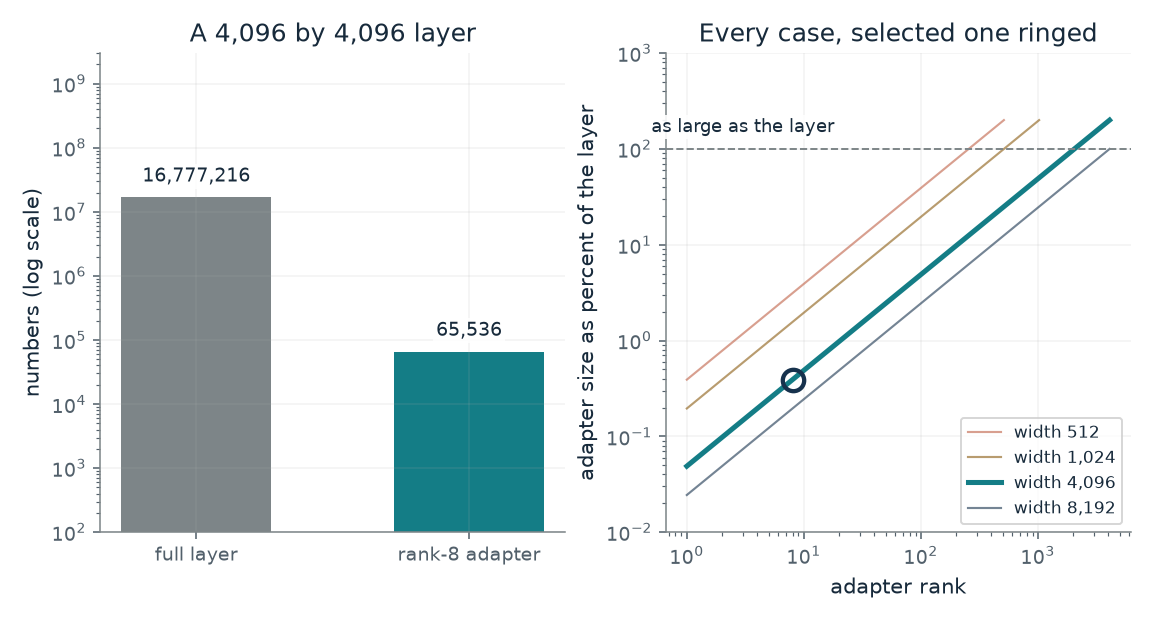

- **Numbers in the full layer:** 16,777,216
- **Numbers in the adapter:** 65,536
- **Adapter share of the layer:** 0.391 percent (1 in 256)
- **Rank at which the adapter is as large as the layer:** 2,048

A 4,096 by 4,096 layer holds 16,777,216 numbers. A rank-8 adapter holds 65,536, which is 0.391 percent. The adapter stops saving anything at rank 2,048, half the width.

Full layer: 4,096 x 4,096 = 16,777,216. Adapter: B has 4,096 x 8 and A has 8 x 4,096, so 2 x 4,096 x 8 = 65,536. Share = 2 x 8 / 4,096 = 0.003906.

In [3]:
figure, values, explanation = size_picture(**{'layer': 4096, 'rank': 8})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How small is a rank-8 adapter on a real layer?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Layer width d = 4096, Adapter rank r = 8: A 4,096 by 4,096 layer holds 16,777,216 numbers and a rank-8 adapter holds 65,536, which is 0.39 percent, or 1 in 256. The adapter would be as large as the layer at rank 2,048, half the width.

**Takeaway:** At real width a small rank gives a tiny adapter, and the share is simply 2r divided by d.

**Why it matters:** A company that wanted one fine-tuned copy per customer would store a full copy each time. An adapter makes the saved difference small, though the protection of the old skill comes from keeping the original separate, not from the size.

**In machines:** The count is an arithmetic identity. How much old skill a small adapter protects is an empirical question, and the chapter's studies disagree by domain.

**Where it applies:** A single square layer, with the adapter counted as the two thin grids. Real models have many layers and adapt only some of them, so the saving for a whole model depends on which layers are adapted.

**Check your understanding:** How many numbers does a rank-16 adapter hold on a 1,024 by 1,024 layer, and what share of the layer is that?

<details><summary>Show the answer</summary>

2 x 1,024 x 16 = 32,768 numbers against 1,048,576, which is 3.125 percent.

</details>

*Source: Chapter 27, Changing the weights on purpose is routine, and a small adapter makes it cheap. Book arithmetic: the chapter's 4,096 by 4,096 layer with 16,777,216 numbers and a rank-8 adapter of 65,536, about 0.4 percent. The other widths and ranks are this companion's variations. The LoRA paper's measured savings on GPT-3 are not computed here.*

## C27-D03: How far does each weight move when a penalty guards the old task?

Both weights sit at 2 after task A. Task B alone would pull both to 0. The first weight mattered to A (Fisher number 4) and the second hardly did (0.25). With lambda 1, where does each weight settle?

Each weight is pulled two ways: the new task pulls it toward 0 with strength 1, and the penalty pulls it back to 2 with strength lambda times its Fisher number. The weight settles at the weighted average of the two targets, each counted by its strength.

$$
L(\theta)=L_B(\theta)+\sum_i\frac{\lambda}{2}F_i\bigl(\theta_i-\theta^{*}_{A,i}\bigr)^2,\qquad \theta_i=\frac{\lambda F_i\,\theta^{*}_{A,i}}{1+\lambda F_i}
$$

**Symbols:** L_B: the loss on the new task alone, here (theta_1^2 + theta_2^2) / 2; theta*_A,i: weight i after learning task A (2 for both); F_i: the Fisher number: how sensitive the old task is to weight i; lambda: how much the old task counts; 0 ignores it and a large value pins the weights

**Predict before looking:** Predict which weight moves more and by roughly how much, then predict where both settle if lambda is raised to 20.

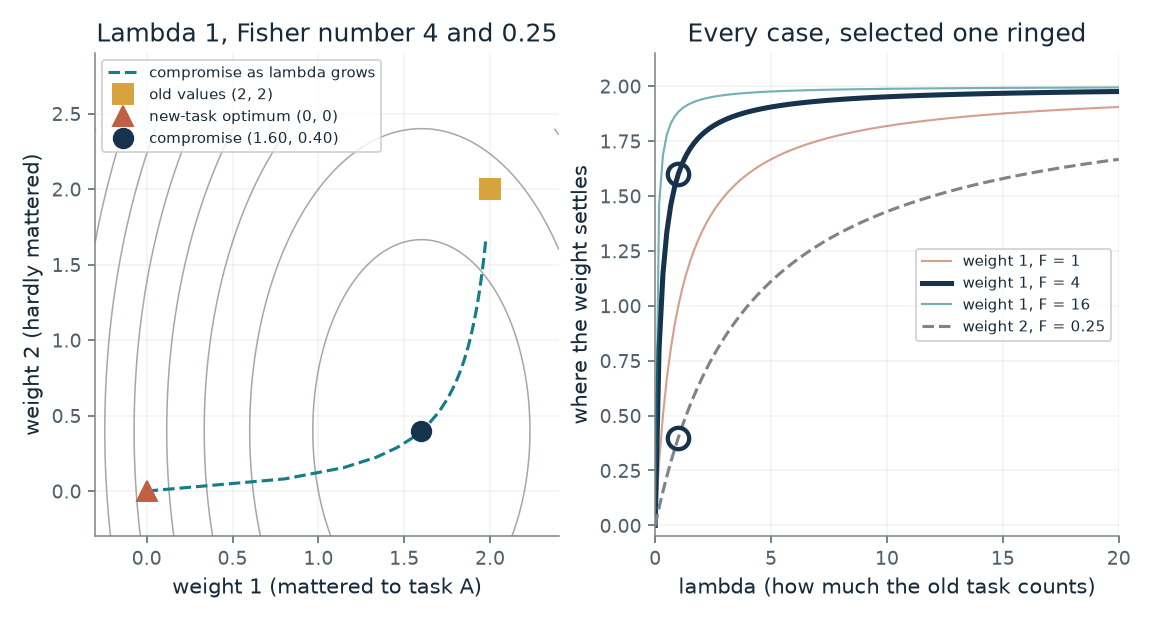

- **Weight 1 settles at:** 1.6
- **Weight 2 settles at:** 0.4
- **Total cost at (2, 2) and at (0, 0):** 4 and 8.5
- **Total cost at the compromise:** 2

At lambda 1 the weight that mattered (Fisher number 4) settles at 1.6, moving 0.4 from 2, and the weight that hardly mattered settles at 0.4, moving 1.6. A larger lambda keeps both nearer 2.

Position = (lambda F x 2) / (1 + lambda F). Weight 1: (4 x 2) / (1 + 4) = 1.6. Weight 2: (0.25 x 2) / (1 + 0.25) = 0.4. Cost = new-task loss 1.36 + penalty 0.64 = 2.

In [4]:
figure, values, explanation = ewc_picture(**{'lam': 1.0, 'f1': 4.0})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='How far does each weight move when a penalty guards the old task?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Lambda = 1.0, Fisher number of weight 1 = 4.0: The weight that mattered settles at 1.6 and the one that hardly mattered at 0.4. Staying at (2, 2) costs 4.00, moving to (0, 0) costs 8.50 (all of it the penalty), and the compromise costs 2.00. A larger lambda keeps both nearer 2.

**Takeaway:** Each weight settles at a weighted average of the new target and its old value, pulled toward the old value in proportion to lambda times its Fisher number.

**Why it matters:** The penalty slows the loss of an old skill by making the weights that mattered stiff. The price is new skill: with large lambda the new task is served less. It also needs two stored numbers per weight.

**In brains and behavior:** A short-lived tag marks a synapse in rat brain slices, and the chapter calls the likeness to this penalty its own analogy, not a claim in either paper.

**In machines:** A specification: the penalty is a spring on each weight, stiff where the Fisher number is large.

**Where it applies:** Two weights, a quadratic new-task loss and a diagonal penalty. The authors tested the method on shuffled digits and Atari games, not on large language models, and note it underestimates how uncertain the weights are.

**Check your understanding:** With lambda 1 and Fisher numbers 4 and 0.25, show that weight 2 settles at 0.4.

<details><summary>Show the answer</summary>

The old pull has strength 0.25 x 1 = 0.25. The position is (0.25 x 2) / (1 + 0.25) = 0.5 / 1.25 = 0.4.

</details>

*Source: Chapter 27, New training can wipe out old skill, and a penalty can slow the loss. Book formula (elastic weight consolidation, Kirkpatrick and colleagues 2017) and the chapter's constructed two-weight example: old values 2 and 2, Fisher numbers 4 and 0.25, lambda 1, giving 1.6 and 0.4 with total cost 2.00. The other lambdas and the first Fisher number are this companion's variations. The weighted-average rule is exact for this quadratic. No simulation.*

## C27-D04: What did the taxi trainees' training look like, and what could the scan show?

Of 79 men starting the training for London taxi licensing, 39 qualified and 20 who returned did not. The qualified men showed more gray matter in the back of the hippocampus. How different was the training of the two groups?

Each bar is a group mean from the study's Table 1. The ratio on the right divides the not-qualified mean by the qualified mean. Months of training are nearly equal, so the group difference the study reports is in hours per week and in test appearances. These are measures of how intense the training was, not of effort itself.

$$
\text{ratio}=\frac{\text{did not qualify}}{\text{qualified}}
$$

**Symbols:** qualified: the 39 trainees who qualified and returned for the second scan; did not qualify: the 20 trainees who did not qualify and returned; ratio: this companion's own descriptive ratio of the two group means

**Predict before looking:** Before choosing a measure, predict which of the three (months of training, hours per week, test appearances) was most similar between those who qualified and those who did not.

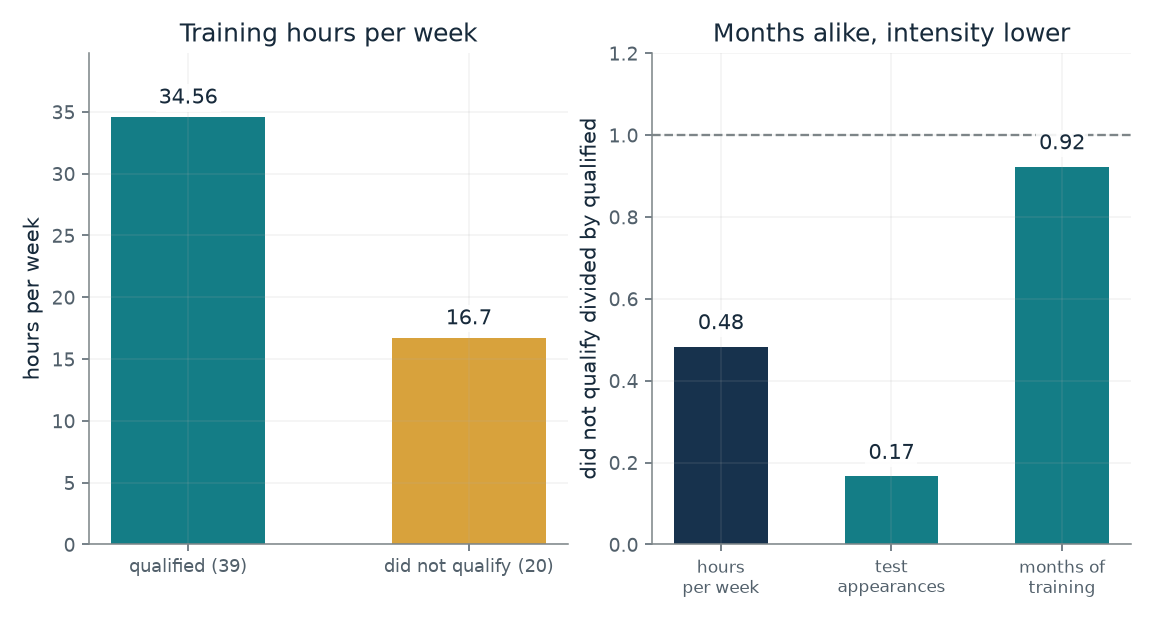

- **Qualified:** 34.56 hours per week
- **Did not qualify:** 16.7 hours per week
- **Ratio, not qualified to qualified (companion's arithmetic):** 0.48
- **Cohort:** 79 started; 59 returned (39 and 20); 31 comparison men

On training hours per week, the men who did not qualify had 16.7 against 34.56 for those who did, a ratio of 0.48. Total months of training were similar (38.8 against 35.8), while weekly hours and appearances were far lower.

Ratio = 16.7 / 34.56 = 0.483. Cohort check: 39 + 20 + 20 who did not return = 79 at the first scan.

In [5]:
figure, values, explanation = taxi_picture(**{'measure': 'hours'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt="What did the taxi trainees' training look like, and what could the scan show?"))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Which measure = hours: Total months of training were about the same (38.8 and 35.8), but the men who did not qualify trained 16.70 hours a week against 34.56, about half, and made 2.60 test appearances against 15.64. The authors argue the gray-matter change came from acquiring the map, not from the effort of trying, because the men who failed studied the same streets. They leave open whether people who qualify differ from the start.

**Takeaway:** The two groups trained for about the same number of months, but those who did not qualify trained about half as many hours per week and made far fewer appearances.

**Why it matters:** This book reads the taxi study as one of the better designs, because of the men who studied and failed. The scan result is evidence that an adult brain can keep changing with use, not evidence of how learning works at the cell level.

**In brains and behavior:** Gray matter in the posterior hippocampi rose in the qualified men only, and the qualified men did worse on delayed recall of a complex figure. The study did not test whether the hippocampal change caused the drop. The mathematics of a brain is a model, and this is a reported structural result, not a model.

**Where it applies:** An MRI scan measures how much tissue sits in a region and does not show which cells changed or whether connections did. The study covers only men, one city and one skill. A 2013 review questioned whether the reported analysis established a difference in change between groups. The authors leave open whether people who qualify differ from the start in how readily the hippocampus changes.

**Check your understanding:** Why does the similar total training time not by itself show that the training was equally intense in the two groups?

<details><summary>Show the answer</summary>

Months are a duration, while hours per week and appearances measure intensity. The not-qualified men trained about half as many hours per week and made far fewer appearances, so by those measures their training was less intense even over similar months. The authors still argue the gray-matter change came from acquiring the map, and they leave open whether people who qualify differ from the start in how readily the hippocampus changes.

</details>

*Source: Chapter 27, Chapter 27: Learning After Training. Reported values quoted in the chapter and its source note from Woollett and Maguire (2011): 79 trainees at the first scan, 59 returned (39 qualified, 20 not), 20 did not return, 31 comparison men; Table 1 training figures: total training time 38.8 months (qualified) against 35.8 (not qualified), hours per week 34.56 against 16.70, appearances 15.64 against 2.60. The ratios are this companion's arithmetic. No simulation or model is used here.*

## C27-D05: In a toy network, what does each fix save, and what does it cost?

A small network learns task A, is trained on task B (the same cards with the 16 measurements shuffled), and forgets A. Which of replay, a penalty and a small adapter protects A, and at what price?

After learning A the network scores about 99 on A and 37 on B. Plain training on B for 1,500 updates reaches about 99 on B but drops A to about 79. Each fix changes the training: replay adds old cards, the penalty pulls weights toward their old values, and the adapter changes only a small add-on.

$$
\text{forgetting}=\text{accuracy on A after A}-\text{accuracy on A after B}
$$

**Symbols:** accuracy: the share of 900 fresh cards sorted correctly; guessing is one third; replay: mixing some old task-A cards into the task-B training; penalty: the elastic weight consolidation penalty of the previous demonstration, with lambda 10 or 1,000; adapter: a rank-2 add-on to the first layer, 56 numbers, with the rest frozen

**Predict before looking:** Predict whether a small adapter keeps task A better or worse than plain fine-tuning, and what happens to A when the adapter is removed.

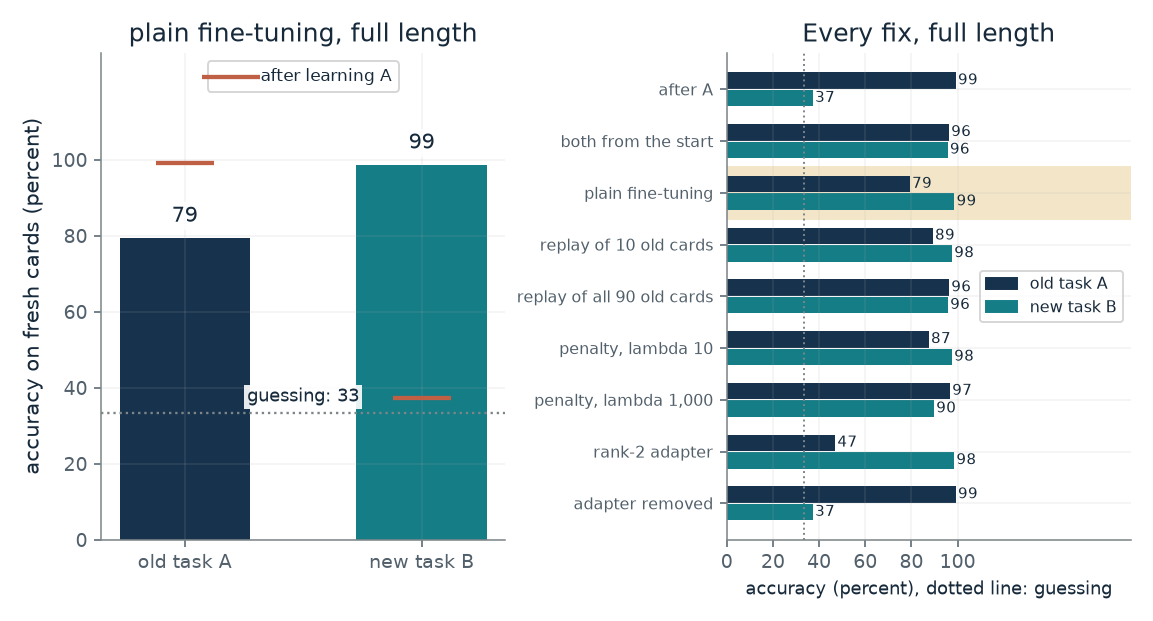

- **Old task A:** 79 percent
- **New task B:** 99 percent
- **Change on A from before B:** -20 points
- **Extra to store:** nothing extra

Plain fine-tuning (full length) leaves task A at 79 percent and task B at 99. Before B, A was 99 and B 37. This is the average of 20 seeded versions of a toy network, a companion rerun of the chapter's script, not a model of a real system.

Accuracy is the share of 900 fresh cards sorted correctly, averaged over 20 random versions (seeds 0 to 19); guessing is 33 percent. Network: 16 inputs, 12 tanh units, 3 outputs, 243 weights. 1,500 updates per stage at learning rate 0.2.

In [6]:
figure, values, explanation = toy_picture(**{'fix': 'plain', 'stop': 'full length'})
buffer = io.BytesIO()
figure.savefig(buffer, format='png', dpi=140, bbox_inches='tight', pad_inches=0.16)
display(Image(data=buffer.getvalue(), alt='In a toy network, what does each fix save, and what does it cost?'))
plt.close(figure)
display(Markdown('\n'.join('- **' + str(k) + ':** ' + str(display_value(v)) for k, v in values.items())))
display(Markdown(clean_display_text(explanation['summary'] if isinstance(explanation, dict) else explanation)))
if isinstance(explanation, dict) and explanation.get('calculation'):
    display(Markdown(clean_display_text(explanation['calculation'])))

**What happens:** At Which fix = adapter2, How long to train on B = full length: The rank-2 adapter learns task B (about 98 percent) but leaves task A at about 47 percent, worse than plain fine-tuning at about 79. A small number of trained weights is not a small change: the adapter's change to the first layer was about twice plain fine-tuning's. Removing the adapter brings back the original network exactly, with A near 99 and B near 37. That holds by construction, since the original weights were frozen, so it checks the code and is not a finding.

**Takeaway:** In the toy, replay and the penalty protected the old task at a price in storage or in new skill, a first-layer adapter did not, and removing the adapter restores the old network (by construction) and loses the new skill.

**Why it matters:** Replay needs the old data, the penalty trades new skill for old, and the adapter's gain is that it can be taken off. The chapter's comparison of a stored note, an adapter and retraining with old examples is a proposal that nobody has tested.

**In brains and behavior:** The stored old cards play the part that replayed memories play in the brain proposal. The brain is not known to keep a verbatim copy, and the toy does not test sleep replay.

**In machines:** A constructed network and a gradient-descent specification. Interleaving old cards helped in the toy in the same direction as the 1995 simulations the chapter cites, in a different network.

**Where it applies:** Task B reshuffles every input, a demanding case for a first-layer adapter. The size of the forgetting depends on how long training runs: the early-stop version ends the B stage once 95 percent of its 90 training cards are sorted correctly, and plain fine-tuning then loses far less. The toy does not show that real adapters forget more, and the chapter's own Llama-2 source found the opposite in code.

**Check your understanding:** In the full-length setting, which fix that still learns task B leaves old task A highest, and what does it cost on task B?

<details><summary>Show the answer</summary>

The penalty with lambda 1,000 keeps A at about 97 and costs B (about 90 against 99 for plain fine-tuning). Replay of all 90 old cards leaves A near 96 and B near 96, but needs the old cards stored. Removing the adapter leaves A at about 99, the highest of all, but it takes B back to about 37, so it does not count as a fix that learns B.

</details>

*Source: Chapter 27, The build: in a small toy, replay and a penalty protected the old task, and a first-layer adapter did not. The chapter's own small simulation (its script toy_checks_27.py), ported here with the same protocol: 16 inputs, 12 tanh units, 3 outputs, 243 weights; 90 training cards per task, 900 test cards; learning rate 0.2; 1,500 updates per stage; 20 seeded versions (seeds 0 to 19), averaged. It is the book's analysis, not a published study and not a model of a real system. Replay uses evenly spaced old cards.*

## Bring it to your own question

Ask what must be kept (old examples, old weights and sensitivity numbers, or the adapter), what is lost (new skill, old skill, or time), and whether the change can be undone. Use the adapter card for sizes, the penalty card for how far each weight moves, and the toy card for the direction and price of each fix in a small case. Say that the toy is not a published study and does not show that real adapters forget more.

Use the `mmi-ch27-learning-after-training` skill to choose a relevant equation, work with your inputs, and interpret the result. The skill should explain the assumptions and distinguish an illustration from evidence about your particular situation.